# Statistics

In [105]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from scipy import optimize, stats
from matplotlib.animation import FuncAnimation, PillowWriter

plt.style.use('ggplot')

## Summarizing Data

- Point estimate: "In statistics, point estimation involves the use of sample data to calculate a single value, which serves as a "best guess" or "best estimate" of an unknown quantity, for example, the population mean, the variance of a distribution, or a model parameter." (Wikipedia)

## When summarizing a dataset by a single number is okay?

Depends on what one wants to extract from the dataset. However, we lose a *lot* of information in this way.

READ THIS BOOK by Sanjay Mahajan if you want to understand how we model a system in Science. [Free copy from the author](https://direct.mit.edu/books/oa-monograph/5345/The-Art-of-Insight-in-Science-and). This image is from his book (p. xv)
![](mahajan-complexity.png)


## Histogram

By partitioning the data into bins (intervals) and showing the frequency of data points that fall within each bin, a histogram shows how a numerical data is distributed. They are useful in data analysis to identify patterns or anomalies in the distribution.

From Wikipedia

> "A histogram is a visual representation of the distribution of quantitative data. The term was first introduced by Karl Pearson. To construct a histogram, the first step is to "bin" (or "bucket") the range of values— divide the entire range of values into a series of intervals—and then count how many values fall into each interval. The bins are usually specified as consecutive, non-overlapping intervals of a variable. The bins (intervals) are adjacent and are typically (but not required to be) of equal size."

> "Histograms give a rough sense of the density of the underlying distribution of the data, and often for density estimation: estimating the probability density function of the underlying variable."

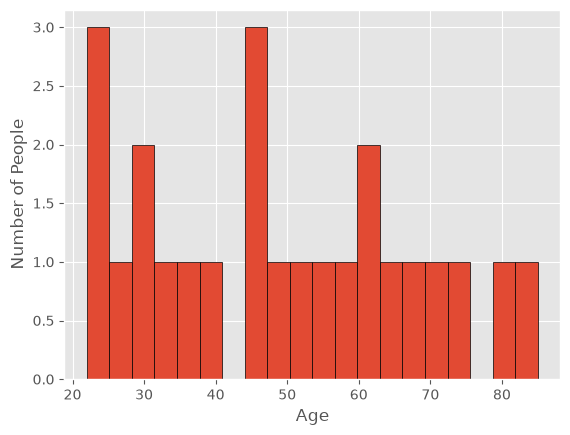

In [106]:
ages = np.array([22, 23, 25, 27, 29, 30, 32, 35, 40, 45, 46, 47, 50, 52, 55, 57, 60, 61, 65, 68, 70, 75, 80, 85])
plt.hist(ages, bins=20, edgecolor="black")
plt.xlabel("Age")
plt.ylabel("Number of People")
pass;

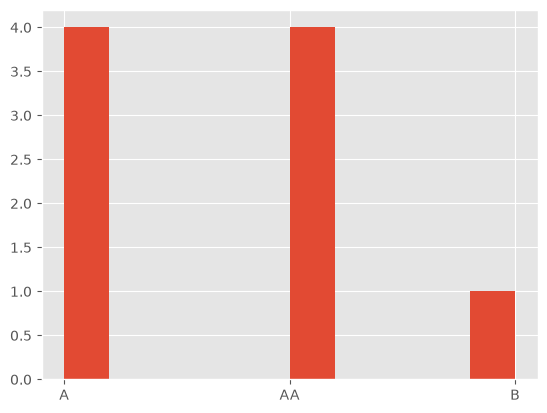

In [107]:
lst = ['A','A','A','A','AA','AA','AA','AA','B']
plt.hist(lst);

## Few distributions

- Gavin Crooks wrote down a superb list of continuous distributions  [pdf](https://threeplusone.com/pubs/FieldGuide.pdf)
- Check the [Numpy docs](https://numpy.org/doc/stable/reference/random/legacy.html) for more on possible distributions

### In the next cell we mentioned the following distributions
- Normal: $f(x) = \frac{1}{\sigma\sqrt{2\pi}} e^{-\frac{(x-\mu)^2}{2\sigma^2}}$. Mean $\mu$ = loc, standard deviation $\sigma$ = scale; here it is the standard normal, a symmetric bell curve.
- Uniform: $f(x) = \frac{1}{b-a}, \quad a \le x \le b$. Every value in $[a, b)$ is equally likely with $a<b$
- Binomial: $P(X=k) = \binom{n}{k} p^k (1-p)^{n-k}$. Counts the number of successes $k$ in $n$ independent trials, each with success probability $p$.
- Poisson: $P(X=k) = \frac{\lambda^k e^{-\lambda}}{k!}$. Counts events in a fixed interval at an average rate $\lambda$ = lam, where mean and variance both equal $\lambda$.
- Exponential: $f(x) = \frac{1}{\beta} e^{-x/\beta}, \quad x \ge 0$. Models the waiting time between Poisson events, where $\beta$ = scale = $1/\lambda$ is the mean wait.

In [108]:
normal_dist = np.random.normal(loc=0, scale=1, size=10000)
uniform_dist = np.random.uniform(low=0, high=1, size=10000)
binomial_dist = np.random.binomial(n=10, p=0.5, size=10000)
poisson_dist = np.random.poisson(lam=3, size=10000)
exponential_dist = np.random.exponential(scale=1, size=10000)

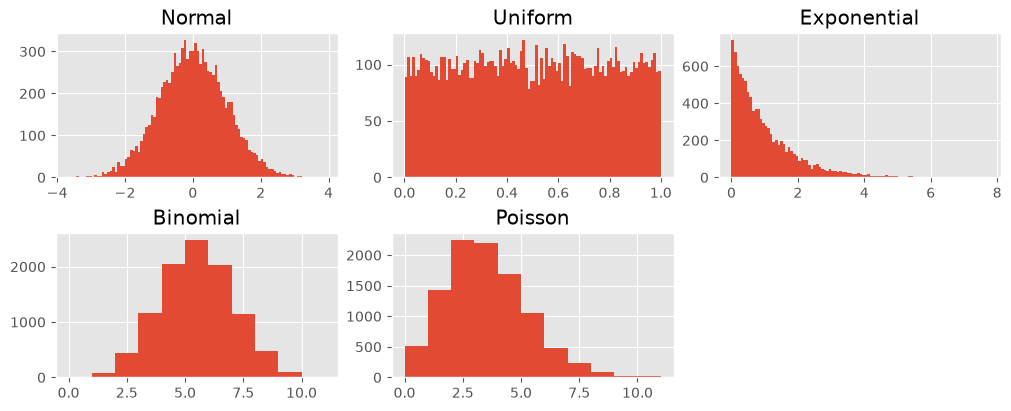

In [109]:
bns = 100
fig, axes = plt.subplots(2, 3, figsize=(10, 4), constrained_layout=True)
axes[0,0].hist(normal_dist, bins=bns); axes[0,0].set_title('Normal')
axes[0,1].hist(uniform_dist, bins=bns); axes[0,1].set_title('Uniform')
axes[0,2].hist(exponential_dist, bins=bns); axes[0,2].set_title('Exponential')
axes[1,0].hist(binomial_dist, bins=range(12)); axes[1,0].set_title('Binomial')
axes[1,1].hist(poisson_dist, bins=range(12)); axes[1,1].set_title('Poisson')
axes[1,2].axis('off');

## Point estimates

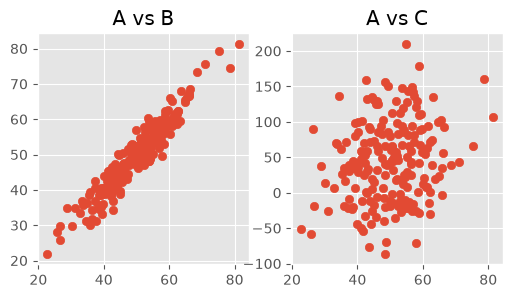

In [110]:
df = pd.DataFrame(columns=['A','B','C'])
df['A'] = np.random.normal(50, 10, 200)
df['B'] = df['A'] + np.random.normal(0,3,200)
df['C'] = df['A'] + np.random.normal(0,50,200) # this is a monster

fig,ax=plt.subplots(1,2,figsize=(6,3))
ax[0].scatter(df['A'],df['B'])
ax[0].set_title('A vs B')
ax[1].scatter(df['A'],df['C'])
ax[1].set_title('A vs C');



- Mean - the average of all values
- Median - the middle value when sorted
- Mode - the most common value
- Variance - average of squared distances from the mean
- Standard deviation - square root of variance, spread in original units
- Range - max - min
- IQR - spread of the middle 50% of the data

In [111]:
s = df['A']

mean = s.mean()
median = s.median()
mode = s.mode()[0]
variance = s.var()
std = s.std()
data_range = s.max() - s.min()
iqr = s.quantile(0.75) - s.quantile(0.25)

pd.Series({
    'mean': mean, 'median': median, 'mode': mode,
    'variance': variance, 'std': std,
    'range': data_range, 'IQR': iqr
})

mean        49.760460
median      50.429519
mode        22.745738
variance    97.240411
std          9.861055
range       58.736710
IQR         13.705764
dtype: float64

## Errors and Uncertainty

- Standard error (SEM): how far the sample mean is likely to be from the population mean
- Absolute error: difference between measured and true value
- Relative error: absolute error as a percentage of the true value
- RMSE: typical size of errors, penalizes big errors more

In [112]:
true_value = 50
measured = np.random.normal(true_value, 2, 30)
measured
abs_error = np.abs(measured - true_value)
rel_error = abs_error / true_value
rmse = np.sqrt(np.mean((measured - true_value) ** 2))

pd.Series({
    'mean_abs_error': abs_error.mean(),
    'mean_rel_error_%': rel_error.mean() * 100,
    'rmse': rmse
})

array([49.90517418, 49.69508102, 52.22589527, 51.10288519, 48.51153974,
       52.19032365, 48.45137238, 53.73453345, 49.54485149, 49.10229006,
       51.62741253, 50.40988206, 48.85872825, 47.6187567 , 49.68642563,
       48.50357021, 47.47824305, 51.06201152, 50.76437098, 46.54624479,
       49.01477033, 48.49902976, 50.37577521, 51.79840945, 51.15288491,
       50.26751207, 50.30414906, 53.0579767 , 51.29882   , 52.76859762])

mean_abs_error      1.424179
mean_rel_error_%    2.848357
rmse                1.727873
dtype: float64

## Interpreting Data

- Correlation: how two variables are related (-1 to 1)
- Outlier: a value unusually far from the rest of the data

0.9536517500952093
0.20924780474600754


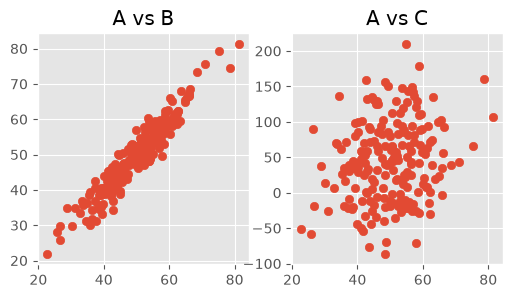

In [113]:
fig,ax=plt.subplots(1,2,figsize=(6,3))
ax[0].scatter(df['A'],df['B'])
ax[0].set_title('A vs B')
ax[1].scatter(df['A'],df['C'])
ax[1].set_title('A vs C')

print(df['A'].corr(df['B']))
print(df['A'].corr(df['C']));

## Boxplot

Seaborn boxplot shows the distribution of a numeric variable using five values: minimum, $Q_1$, median, $Q_3$, maximum.

Quartiles divide sorted data into four equal parts, each containing about 25% of the observations.

- $Q_1$ (first quartile): the value below which 25% of the data lies
- $Q_2$ (second quartile, median): the value below which 50% of the data lies
- $Q_3$ (third quartile): the value below which 75% of the data lies

Interquartile range: $IQR = Q_3 - Q_1$

- Top cap: largest data point within the upper fence, $Q_3 + 1.5\,IQR$
- Top edge of box: $Q_3$, the 75th percentile
- Line inside box: median, $Q_2$
- Bottom edge of box: $Q_1$, the 25th percentile
- Bottom cap: smallest data point within the lower fence, $Q_1 - 1.5\,IQR$


Outlier condition: $x < Q_1 - 1.5\,IQR \quad \text{or} \quad x > Q_3 + 1.5\,IQR$

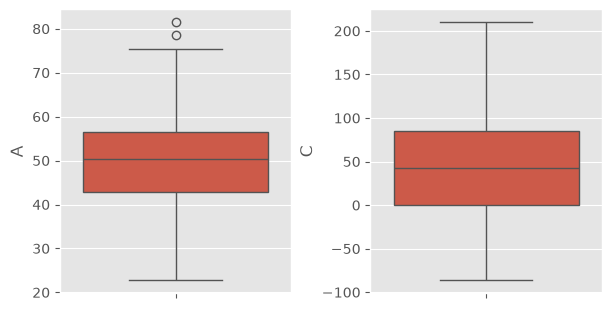

In [114]:
import seaborn as sns
fig,ax=plt.subplots(1,2,figsize=(6,3),constrained_layout=True)

sns.boxplot(df['A'],ax=ax[0])
sns.boxplot(df['C'],ax=ax[1]);

## Simulation

In [115]:
# import random

# def coin_toss():
#     return random.choice([1, 0])
# coin_toss()
# # Simulate N coin tosses
# for _ in range(3):
#     coin_toss()

In [116]:
# N = 1000  # increase the number of tosses. what do you expect to happen?
# tosses = [coin_toss() for _ in range(N)]  # list comprehension
# # print(tosses)
# count_H = 0
# count_T = 0
# for toss in tosses:
#     if toss == 1:
#         count_H = count_H + 1
#     else:
#         count_T = count_T + 1
# print(count_H, count_T, count_H / len(tosses), count_T / len(tosses))
# plt.hist(tosses)#, bins=[-0.5, 0.5, 1.5], density=True)
# plt.xticks([0, 1]);

In [117]:
# # Counting heads in two coin tosses. label 'H' by 1 and 'T' by 0. Is the result expected? what do you need to make it closer to expected?
# trials = 1000
# for i in range(1, trials + 1):
#     # print(f"Number of trials = {i}")
#     count = 0
#     sum = []
#     for j in range(1, i + 1):
#         # draw randomly from {0,1}, TWICE
#         random_array = np.random.binomial(1, 0.5, size=2)
#         sum_i = np.sum(random_array)
#         # print(f"Outcome {j} = {random_array} and number of heads = {sum_i}")
#         sum.append(sum_i)
# # print(sum)
# # Counter([1,2,2,3,4])
# print(Counter(sum))
# plt.bar(Counter(sum).keys(), Counter(sum).values(), width=0.1)
# # pass;

In [118]:
# n_steps = 300
# n_walks = 10

# # generate random steps of -1 or 1 for each walk

# # documentation: https://numpy.org/doc/stable/reference/random/generated/numpy.random.choice.html
# # IMPORTANT: Always look up documentation! Other than 'how to use it', it often points to the method's limitation (and sometimes provide suggestions for other relevant tools.) For example, why you shouldn't use numpy random module if you care about security or cryptography: https://numpy.org/doc/stable/reference/random/index.html

# steps = np.random.choice([-1, 1], size=(n_walks, n_steps))
# # print(f"Step chosen: {steps}")
# # compute cumulative sum along each row to get final positions. Notice that the final element in each row is the final position.
# walks = np.cumsum(steps, axis=1)
# # print(f"Position at each time step: {walks}")

# for i in range(n_walks):
#     plt.plot(walks[i], label=f"Walk {i+1}")

# plt.title("Multiple 1D Random Walk Trajectories")
# plt.xlabel("Steps")
# plt.ylabel("Position")
# pass;
# # plt.legend();

In [119]:
# # Number of steps and number of walks
# n_steps = 100
# n_walks = 1000

# steps = np.random.choice([-1, 1], size=(n_walks, n_steps))
# walks = np.cumsum(steps, axis=1)
# # print(walks)
# # as I mentioned, the last element is the final position in each step
# final_positions = walks[:, -1]
# # print(final_positions)

# # Plot the distribution of final positions. Remember: it's the histogram of final positions that has a normal distribution.

# plt.hist(final_positions, bins=100, density=True)
# plt.title("Distribution of final positions in 1D random walks")
# plt.xlabel("Final position")
# plt.ylabel("Density")
# pass;

In [120]:
# # a code to create a RW animation, written by me with helps from ChatGPT (regarding some visualization improvements)

# n_steps = 200
# n_walks = 10

# np.random.seed(42)
# walks = np.random.choice([-1, 1], size=(n_walks, n_steps)).cumsum(axis=1)

# fig, ax = plt.subplots(figsize=(8, 4))
# ax.set_xlim(0, n_steps)
# ax.set_ylim(walks.min() - 5, walks.max() + 5)
# ax.set_xlabel('Steps')
# ax.set_ylabel('Position')
# ax.axhline(0, color='gray', lw=1, ls='--', alpha=0.7)
# ax.grid(True, linestyle=':', alpha=0.2)

# lines = [ax.plot([], [], color="black", lw=1, alpha=0.5)[0] for _ in range(n_walks)]
# mean_line, = ax.plot([], [], lw=2.5, c='red')
# std_fill = ax.fill_between([], [], [], color='red', alpha=0.15)

# def init():
#     for line in lines: line.set_data([], [])
#     mean_line.set_data([], [])
#     std_fill.set_verts([])
#     ax.set_title("Random Walks")
#     return lines + [mean_line, std_fill]

# def update(frame):
#     if frame == 0: return lines + [mean_line, std_fill]
#     for i, line in enumerate(lines):
#         x = np.arange(frame); y = walks[i, :frame]
#         line.set_data(x, y)
#         line.set_marker('o'); line.set_markevery([frame-1])
#     x = np.arange(frame)
#     mean = walks[:, :frame].mean(axis=0); std = walks[:, :frame].std(axis=0)
#     mean_line.set_data(x, mean)
#     verts = np.concatenate([np.column_stack([x, mean-std]),
#                             np.column_stack([x[::-1], (mean+std)[::-1]])])
#     std_fill.set_verts([verts])
#     ax.set_title(f"Random Walks (Step {frame}/{n_steps})")
#     return lines + [mean_line, std_fill]

# ani = FuncAnimation(fig, update, frames=n_steps, init_func=init,
#                     blit=False, interval=20)
# ani.save('random_walk.gif', writer=PillowWriter(fps=60))
# plt.show();


## Linear Regression

[Wikipedia](https://en.wikipedia.org/wiki/Ordinary_least_squares) has an excellent article. Please read it.

slope = 2.52, intercept = 4.36


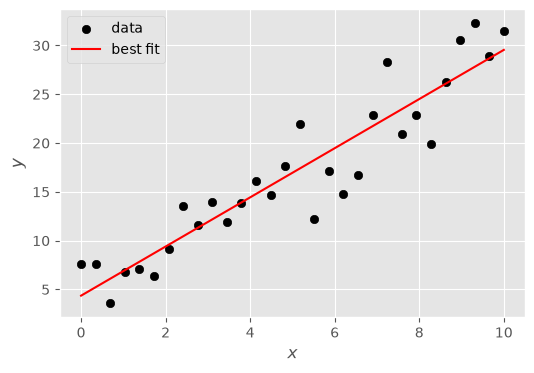

In [132]:
x = np.linspace(0, 10, 30)
y_true = 2.5 * x + 5
# y = y_true
y = y_true + np.random.normal(0, 3, size=x.size)

df = pd.DataFrame({'x': x, 'y': y})

# https://en.wikipedia.org/wiki/Coefficient_of_determination (for r value)
slope, intercept, r_value, p_value, std_err = stats.linregress(df['x'], df['y'])

print(f'slope = {slope:.2f}, intercept = {intercept:.2f}')

y_pred = slope * df['x'] + intercept

plt.figure(figsize=(6,4))
plt.scatter(df['x'], df['y'], label='data', color='black')
plt.plot(df['x'], y_pred, color='red', label='best fit')
plt.xlabel('$x$'); plt.ylabel('$y$'); plt.legend();

## Estimating Parameters from Data (Non-linear Curve)

- Same least-squares idea, but for a curved model using scipy `curve_fit` function ([Documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.curve_fit.html))
- Let's consider a exponential and a quadratic fit (the true data is exponential with normally distributed noise)

In [137]:
x2 = np.linspace(0, 5, 30)
y2_true = 3 * np.exp(0.4 * x2)
# y2 = y2_true
y2 = y2_true + np.random.normal(0, 1.5, size=x2.size)

def exp_model(x, a, b):
    return a * np.exp(b * x)

params, cov = optimize.curve_fit(exp_model, x2, y2, p0=[1, 0.1])
a_fit, b_fit = params
param_errors = np.sqrt(np.diag(cov))

pd.Series({'a': a_fit, 'b': b_fit, 'a_err': param_errors[0], 'b_err': param_errors[1]})

a        2.736379
b        0.430745
a_err    0.316326
b_err    0.028119
dtype: float64

In [134]:
def quadratic_model(x, c, d):
    return c * x**2 + d
params1, cov1 = optimize.curve_fit(quadratic_model, x2, y2, p0=[1, 0.1])
c_fit, d_fit = params1
param_errors1 = np.sqrt(np.diag(cov1))

pd.Series({'c': c_fit, 'd': d_fit, 'c_err': param_errors1[0], 'd_err': param_errors1[1]})

c        0.723318
d        3.555677
c_err    0.005990
d_err    0.068681
dtype: float64

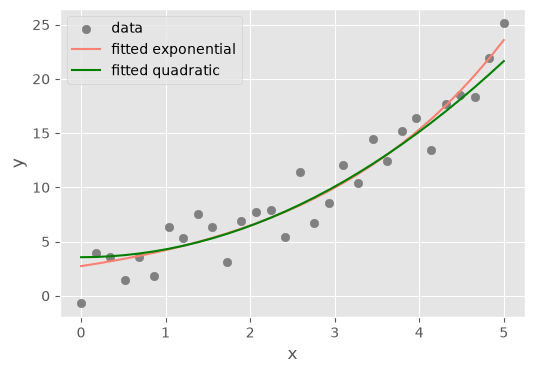

In [138]:
y2_pred = exp_model(x2, a_fit, b_fit)
y2_pred1 = quadratic_model(x2, c_fit, d_fit)

plt.figure(figsize=(6,4))
plt.scatter(x2, y2, label='data', color='gray')
plt.plot(x2, y2_pred, color='salmon', label='fitted exponential')
plt.plot(x2, y2_pred1, color='green', label='fitted quadratic')
plt.xlabel('x'); plt.ylabel('y'); plt.legend();

## Check Fit Quality

- Residuals should look randomly scattered around zero (normally distributed)
- Patterns in residuals mean the model may be wrong
- Large residuals highlight poor-fitting points

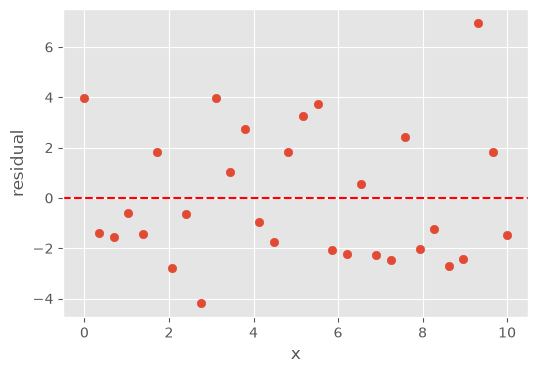

In [125]:
residuals = df['y'] - y_pred

plt.figure(figsize=(6,4))
plt.scatter(df['x'], residuals)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('x'); plt.ylabel('residual');

In [126]:
rss = np.sum(residuals**2)
rmse = np.sqrt(np.mean(residuals**2))

pd.Series({'RSS': rss, 'RMSE': rmse, 'R_squared': r_value**2})

RSS          206.313984
RMSE           2.622429
R_squared      0.889495
dtype: float64

In [127]:
residuals2 = y2 - y2_pred

pd.DataFrame({'x': x2, 'residual': residuals2}).describe()

,x,residual
count,30.000000,30.000000
mean,2.500000,-0.039532
std,1.517829,1.335396
min,0.000000,-2.503111
25%,1.250000,-1.147082
50%,2.500000,0.278007
75%,3.750000,1.082249
max,5.000000,2.255016


## Null Hypothesis Significance Testing ($p$-value)

Reference: Garfinkel, A.; Guo, Y. Understanding Data: A 21st Century Approach to Statistics and Data Science; Springer, 2026. https://doi.org/10.1007/978-3-032-18600-3

Following example is from pp. 96–97 of Garfinkel & Guo

- 52% girl and 48% boy among 300 births in families living near power plants
- Is the power plant affecting the development of the fetus and producing unequal sex ratios?
- Statistical significance: Did it happen by random chance?
- How surprising would it be if it did?
- If the surprise value is high, then it's statistically significant.
- If it's 30% of the time then not significant.
- If it's 0.1% of the time then it not be a random occurrence.

Figures: Garfinkel pp. 101–102
![](garfinken-pvalue1.png)
![](garfinken-pvalue2.png)

Observed: 52.00% girls
Simulated mean: 50.00%, std: 2.89%
One-sided p-value: 0.2655


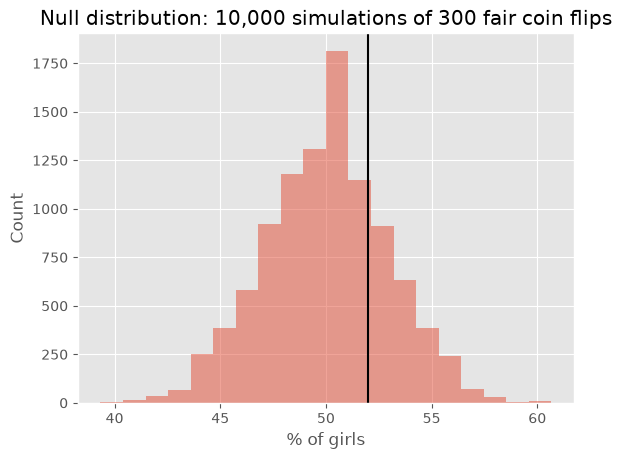

In [128]:
rng = np.random.default_rng(2)

n_flips = 300 # modeling births
n_experiments = 10000 
observed_girls = 156
observed_pct = 100 * observed_girls / n_flips 

# Each experiment: flip a fair coin 300 times (1 = Heads/girl, 0 = Tails/boy),
# count the Heads, and convert to a percentage.
flips = rng.integers(0, 2, size=(n_experiments, n_flips))
pct_heads = 100 * flips.sum(axis=1) / n_flips

# Compare observed to the null distribution
# p-value: how often is a simulated result at least as far from 50% as ours?
p_value = np.mean((pct_heads - 50) >= (observed_pct - 50))

# two-sided p-value
# p_value = np.mean(np.abs(pct_heads - 50) >= abs(observed_pct - 50))

print(f"Observed: {observed_pct:.2f}% girls")
print(f"Simulated mean: {pct_heads.mean():.2f}%, std: {pct_heads.std():.2f}%")
print(f"One-sided p-value: {p_value}")

# Histogram of the null distribution

plt.hist(pct_heads,bins=20,alpha=0.5)
plt.axvline(observed_pct,color='black')
plt.xlabel("% of girls")
plt.ylabel("Count")
plt.title("Null distribution: 10,000 simulations of 300 fair coin flips");

In [129]:
# rng = np.random.default_rng(42)

# def confidence_interval_by_resampling(X, M=np.mean, n_resamples=10000, rng=rng):
#     """99% CI for M_true"""
#     X = np.asarray(X)
#     M_obs = M(X)

#     # resample X with replacement and compute M for each
#     M_i = np.array([M(rng.choice(X, size=len(X), replace=True))
#                     for _ in range(n_resamples)])

#     # rank smallest to largest; M_lower = 50th smallest (MR_50),
#     # M_upper = 50th largest (MR_9951).
#     MR = np.sort(M_i)
#     M_lower = MR[50 - 1]                   # MR_50
#     M_upper = MR[n_resamples - 50]         # MR_9951

#     CI_lower = 2 * M_obs - M_upper
#     CI_upper = 2 * M_obs - M_lower
#     return M_obs, M_i, (M_lower, M_upper), (CI_lower, CI_upper)

# # Example data: 300 births, 156 girls (1) and 144 boys (0)
# X = np.array([1] * 156 + [0] * 144)

# M_obs, M_i, (M_lower, M_upper), (CI_lower, CI_upper) = confidence_interval_by_resampling(X)

# print(f"M_obs   = {100 * M_obs:.1f}%")
# print(f"M_lower = {100 * M_lower:.1f}%, M_upper = {100 * M_upper:.1f}%")
# print(f"99% CI for M_true = ({100 * CI_lower:.1f}%, {100 * CI_upper:.1f}%)")

# # figure
# plt.hist(100 * M_i, bins=30)
# plt.axvspan(100 * CI_lower, 100 * CI_upper, color="#e4f2b3", alpha=0.5, label=f"99% CI: ({100*CI_lower:.1f}%, {100*CI_upper:.1f}%)")
# plt.axvline(100 * M_obs, color="k", ls="--", label="M_obs")
# plt.xlabel("M-value (% girls)")
# plt.ylabel("Count")
# plt.title("A 99% confidence interval for M_true")
# plt.legend();